In [56]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sb
import pickle as p
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler , OneHotEncoder, PowerTransformer
from sklearn.decomposition import PCA
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold, cross_val_predict
from sklearn.metrics import precision_score, recall_score, PrecisionRecallDisplay, RocCurveDisplay, f1_score,roc_auc_score,brier_score_loss, log_loss, fbeta_score, make_scorer
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
from sklearn.calibration import CalibratedClassifierCV, CalibrationDisplay, calibration_curve
from sklearn.frozen import FrozenEstimator
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.inspection import permutation_importance
from sklearn.model_selection import TunedThresholdClassifierCV


In [2]:
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

In [3]:
xg_df= pd.read_csv('data/XG_Features.csv')

In [4]:
xg_df.head()

,match_id,season,team,position,shot_body_part,shot_technique,shot_type,play_pattern,under_pressure,shot_follows_dribble,shot_aerial_won,shot_first_time,shot_one_on_one,shot_open_goal,minute,location_x,location_y,keeper_x,keeper_y,shot_distance_from_goal,shot_angle,shot_angle_visual,distance_between_shooter_and_keeper,distance_between_keeper_and_goal,opponents_within_2_5_yards,opponents_2_5_to_5_yards,opponents_5_to_10_yards,distance_to_nearest_opponent,opponents_in_shot_triangle,player_goal_rate_before,shots_before,goals_for_before,goals_against_before,score_diff_before,shot_outcome_target
0,3773386,2020/2021,Barcelona,Left Wing,Right Foot,Normal,Open Play,From Throw In,0,0,0,0,1,0,12,108.6,28.0,114.5,33.8,16.551737,46.468801,19.470701,8.273452,8.287943,0.0,1.0,0.0,2.863564,0.0,0.230731,35,0,0,0,0
1,3773386,2020/2021,Deportivo Alavés,Right Midfield,Right Foot,Normal,Open Play,Regular Play,0,0,0,1,0,0,16,103.6,51.0,116.3,41.8,19.747405,33.851010,19.332894,15.682155,4.114608,0.0,0.0,2.0,6.525335,0.0,0.098778,4,0,0,0,0
2,3773386,2020/2021,Barcelona,Center Forward,Left Foot,Normal,Open Play,From Throw In,0,0,0,1,0,0,19,104.3,33.9,118.5,37.8,16.843396,21.232892,25.135121,14.725828,2.662705,0.0,1.0,4.0,2.800000,1.0,0.115365,80,0,0,0,0
3,3773386,2020/2021,Barcelona,Center Attacking Midfield,Left Foot,Normal,Free Kick,From Free Kick,0,0,0,0,0,0,22,97.9,44.3,119.6,40.0,22.514440,11.010480,19.806729,22.121935,0.400000,0.0,0.0,0.0,10.231324,7.0,0.203379,2175,0,0,0,0
4,3773386,2020/2021,Deportivo Alavés,Left Midfield,Left Foot,Normal,Open Play,Regular Play,0,0,0,0,1,1,30,118.3,42.1,110.3,44.3,2.701851,51.009006,122.607287,8.296987,10.610372,0.0,0.0,0.0,16.300307,0.0,0.125717,1,0,0,0,1


In [5]:
xg_df.columns

Index(['match_id', 'season', 'team', 'position', 'shot_body_part',
       'shot_technique', 'shot_type', 'play_pattern', 'under_pressure',
       'shot_follows_dribble', 'shot_aerial_won', 'shot_first_time',
       'shot_one_on_one', 'shot_open_goal', 'minute', 'location_x',
       'location_y', 'keeper_x', 'keeper_y', 'shot_distance_from_goal',
       'shot_angle', 'shot_angle_visual',
       'distance_between_shooter_and_keeper',
       'distance_between_keeper_and_goal', 'opponents_within_2_5_yards',
       'opponents_2_5_to_5_yards', 'opponents_5_to_10_yards',
       'distance_to_nearest_opponent', 'opponents_in_shot_triangle',
       'player_goal_rate_before', 'shots_before', 'goals_for_before',
       'goals_against_before', 'score_diff_before', 'shot_outcome_target'],
      dtype='str')

In [6]:
categorical_features = ["team", "position", "shot_body_part", "shot_technique", "shot_type"]

binary_features = ["under_pressure", "shot_follows_dribble", "shot_aerial_won",
                   "shot_first_time", "shot_one_on_one", "shot_open_goal"]
game_state_features = ["goals_for_before", "goals_against_before", "score_diff_before"]
player_features = ["player_goal_rate_before", "shots_before"]

numeric_features = ["minute", "location_x", "location_y", "keeper_x", "keeper_y",
                    "shot_distance_from_goal", "shot_angle", "shot_angle_visual",
                    "distance_between_shooter_and_keeper", "distance_between_keeper_and_goal",
                    "opponents_within_2_5_yards", "opponents_2_5_to_5_yards", "opponents_5_to_10_yards",
                    "distance_to_nearest_opponent", "opponents_in_shot_triangle"] + game_state_features + player_features

target = "shot_outcome_target"
group_column = "match_id"      # brukes til GroupKFold eller lignende, ikke som feature
season_column = "season"       # brukes til splitting/ekstra sjekk, ikke som feature
date_column = "match_date"     # brukes til spillerhistorikk, ikke som feature

features = categorical_features + binary_features + numeric_features
X = xg_df[features]
y = xg_df[target]
groups = xg_df[group_column]
seasons = xg_df[season_column]

In [7]:
xg_df.season.value_counts()

season
2015/2016    972
2017/2018    971
2014/2015    931
2018/2019    887
2016/2017    882
2011/2012    873
2009/2010    843
2020/2021    839
2013/2014    810
2008/2009    765
2019/2020    752
2010/2011    739
2012/2013    721
2007/2008    700
2006/2007    681
2005/2006    433
2004/2005    158
1973/1974     28
Name: count, dtype: int64

In [8]:
test_seasons = ["2018/2019","2019/2020", "2020/2021"]
is_test = xg_df["season"].isin(test_seasons)

trainval_indices = xg_df[~is_test].index
test_indices = xg_df[is_test].index

trainval_featuers = X.loc[trainval_indices]
test_featuers = X.loc[test_indices]

trainval_target= y.loc[trainval_indices]
test_targets = y.loc[test_indices]

In [9]:
train_groups= groups.loc[trainval_indices]

In [10]:
trainval_featuers.columns

Index(['team', 'position', 'shot_body_part', 'shot_technique', 'shot_type',
       'under_pressure', 'shot_follows_dribble', 'shot_aerial_won',
       'shot_first_time', 'shot_one_on_one', 'shot_open_goal', 'minute',
       'location_x', 'location_y', 'keeper_x', 'keeper_y',
       'shot_distance_from_goal', 'shot_angle', 'shot_angle_visual',
       'distance_between_shooter_and_keeper',
       'distance_between_keeper_and_goal', 'opponents_within_2_5_yards',
       'opponents_2_5_to_5_yards', 'opponents_5_to_10_yards',
       'distance_to_nearest_opponent', 'opponents_in_shot_triangle',
       'goals_for_before', 'goals_against_before', 'score_diff_before',
       'player_goal_rate_before', 'shots_before'],
      dtype='str')

In [11]:
#Hjelper metoder 
def show_results(grid, name="", top=5, metric="mean_test_f1"):
    print(f"{name}: beste score = {grid.best_score_:.4f}")
    display(pd.Series(grid.best_params_).astype(str).to_frame("beste verdi"))

    results = pd.DataFrame(grid.cv_results_).sort_values(metric, ascending=False)
    param_cols = results.filter(like="param_").columns.tolist()
    score_cols = [metric, "mean_fit_time"]
    display(results[score_cols + param_cols].head(top))

def show_metrics(grid, name=""):
    results = pd.DataFrame(grid.cv_results_)
    best = results.loc[grid.best_index_]

    table = pd.DataFrame({
        "snitt": [best["mean_test_accuracy"], best["mean_test_precision"],
                  best["mean_test_recall"], best["mean_test_f1"]],
        "std": [best["std_test_accuracy"], best["std_test_precision"],
                best["std_test_recall"], best["std_test_f1"]],
    }, index=["accuracy", "precision", "recall", "f1"])

    print(name)
    display(table.round(3))


In [12]:
pipe_simple = Pipeline([
    ("transformer", ColumnTransformer([
        ("num", 
         Pipeline([
             ("fillna", SimpleImputer(strategy="median", add_indicator=True)),
             ("scaler", StandardScaler()) #Skal fylle den med ulike scalere som standard og minmax
             ]) ,numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_features),
        ("bin", "passthrough", binary_features)
        ])),
    ("estimator", "passthrough"),
])

In [13]:
pipe_advanced = Pipeline([
    ("transformer", ColumnTransformer([
        ("num", Pipeline([
            ("fillna", SimpleImputer(strategy="median", add_indicator=True)),
            ("power", PowerTransformer(method="yeo-johnson", standardize=True)),
            ("pca", PCA(n_components=0.95)),
        ]), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_features),
        ("bin", "passthrough", binary_features),
    ])),
    ("estimator", "passthrough"),
])

In [14]:
gb_params_grid = {
    "estimator": [GradientBoostingClassifier(min_samples_split=50, subsample=0.7)],
    "estimator__n_estimators": [50, 100, 200, 300],
    "estimator__learning_rate": [0.005, 0.01, 0.02, 0.05],
    "estimator__max_depth": [1, 2, 3, 4],
    "estimator__min_samples_leaf": [1, 100],
    "estimator__max_features": [0.2, 0.3],
    "transformer__cat": [OneHotEncoder(handle_unknown="ignore", sparse_output=False)],
}


In [15]:
scoring = {"accuracy": "accuracy", "precision": "precision", "recall": "recall", "f1": "f1"}

In [16]:
sample_goals= np.where(trainval_target == 1, 4, 1)

### Vekting av mål

Bare ca. 13,7 % av skuddene i treningsdataene er mål. Modellen ser altså mange flere bom enn mål. For at den ikke bare skal lære seg å gjette «ikke mål», gir jeg hvert mål vekt 4 og hvert ikke-mål vekt 1.

Det betyr at når Gradient Boosting bommer på et mål, blir den straffet 4 ganger så hardt som når den bommer på et ikke-mål.

Jeg forventer at dette får en bivirkning som jeg ikke har sjekket ennå. Siden feil på mål koster mer, vil modellen trolig skyve sannsynlighetene oppover, slik at de blir for høye i forhold til hvor ofte det faktisk scores. Det påvirker antagelig ikke rangeringen av skuddene så mye, men det kan gjøre at tallene den gir som sannsynlighet ikke stemmer. Det kommer jeg tilbake til når jeg har evaluert modellen.

In [17]:
inner_cv = StratifiedGroupKFold( n_splits=5,shuffle=True, random_state=42)

In [18]:
gb_cv= GridSearchCV(pipe_simple, gb_params_grid,cv=inner_cv,scoring=scoring ,n_jobs=-2, refit="f1", verbose=1)

In [19]:
gb_cv.fit(trainval_featuers, trainval_target, groups=train_groups, 
          estimator__sample_weight=sample_goals)

Fitting 5 folds for each of 256 candidates, totalling 1280 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...assthrough')])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'estimator': [GradientBoost...subsample=0.7)], 'estimator__learning_rate': [0.005, 0.01, ...], 'estimator__max_depth': [1, 2, ...], 'estimator__max_features': [0.2, 0.3], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.","{'accuracy': 'accuracy', 'f1': 'f1', 'precision': 'precision', 'recall': 'recall'}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-2
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'f1'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validat

In [20]:
show_results(grid=gb_cv, name="Gradient Boosting--1143")

Gradient Boosting--1143: beste score = 0.5008


,beste verdi
estimator,GradientBoostingClassifier(min_samples_split=5...
estimator__learning_rate,0.02
estimator__max_depth,4
estimator__max_features,0.3
estimator__min_samples_leaf,1
estimator__n_estimators,50
transformer__cat,"OneHotEncoder(handle_unknown='ignore', sparse_..."


,mean_test_f1,mean_fit_time,param_estimator,param_estimator__learning_rate,param_estimator__max_depth,param_estimator__max_features,param_estimator__min_samples_leaf,param_estimator__n_estimators,param_transformer__cat
184,0.500795,0.831710,GradientBoostingClassifier(min_samples_split=5...,0.020,4,0.3,1,50,"OneHotEncoder(handle_unknown='ignore', sparse_..."
113,0.498499,2.034699,GradientBoostingClassifier(min_samples_split=5...,0.010,4,0.2,1,100,"OneHotEncoder(handle_unknown='ignore', sparse_..."
50,0.497908,2.606667,GradientBoostingClassifier(min_samples_split=5...,0.005,4,0.2,1,200,"OneHotEncoder(handle_unknown='ignore', sparse_..."
58,0.497266,5.311957,GradientBoostingClassifier(min_samples_split=5...,0.005,4,0.3,1,200,"OneHotEncoder(handle_unknown='ignore', sparse_..."
121,0.496969,2.775253,GradientBoostingClassifier(min_samples_split=5...,0.010,4,0.3,1,100,"OneHotEncoder(handle_unknown='ignore', sparse_..."


### Tuning av Gradient Boosting: resultat og hva jeg egentlig er interessert i

Beste F1 i kryssvalideringen ble 0,4993, med learning_rate 0,005, max_depth 3, max_features 0,2, min_samples_leaf 1 og 300 trær.

Jeg har ikke satt random_state. Gradient Boosting bruker tilfeldighet (subsample og max_features), så resultatet varierer litt mellom kjøringene. I stedet for å fikse tilfeldigheten målte jeg den: jeg kjørte tuningen 5 ganger og fikk beste F1 på 0,4982, 0,4988, 0,4993, 0,4986 og 0,4991. Snittet er 0,4988, og standardavviket er ca. 0,0004. Forskjeller på under 0,001 mellom to kombinasjoner er derfor innenfor støyen, og jeg tolker dem ikke som reelle.

F1 er likevel ikke hovedmålet i en xG-modell. Poenget med xG er å vite hvor sannsynlig det er at akkurat dette skuddet blir mål, ikke å gjette om det blir mål eller ikke. F1 krever en hard avgjørelse (mål/ikke mål) og sier ingenting om hvor gode sannsynlighetene er. Jeg brukte F1 til å velge parametere, men det jeg faktisk er interessert i senere, er sannsynlighetene modellen gir.

gjennomsnittet mellom foldsa er viktig å ha med!!

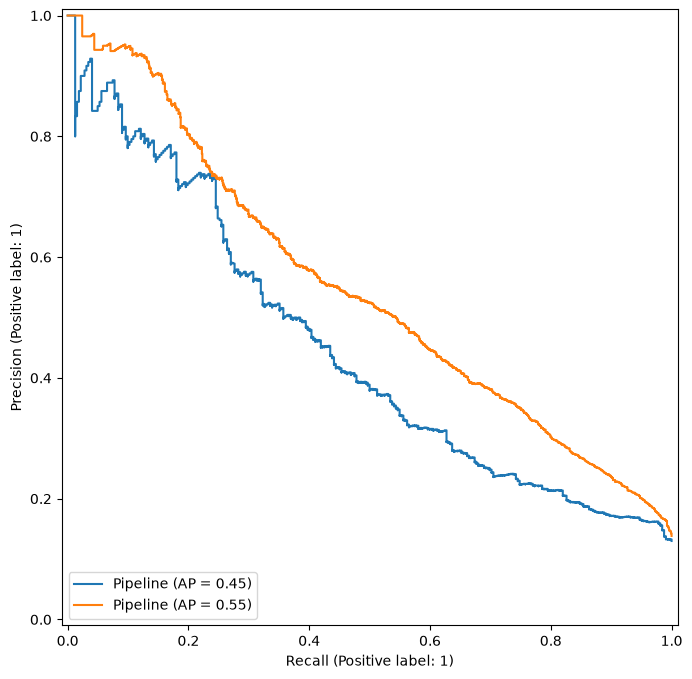

In [21]:
fig, ax = plt.subplots(1, 1,figsize=(10,8))
PrecisionRecallDisplay.from_estimator(gb_cv.best_estimator_, test_featuers, test_targets, ax=ax)
PrecisionRecallDisplay.from_estimator(gb_cv.best_estimator_, trainval_featuers, trainval_target, ax=ax)

### Precision-recall-kurven og hva den sier om terskelvalg

Kurven viser hvordan precision (hvor mange av skuddene jeg kaller mål som faktisk blir mål) og recall (hvor mange av de faktiske målene jeg fanger opp) henger sammen. Hvert punkt på kurven er én terskel. Flytter jeg terskelen lavere, går jeg mot høyre: recall øker, men precision faller.

AP er omtrent arealet under kurven: 0,44 på test mot 0,53 på trainval. Modellen er litt bedre på data den er trent på, men gapet er moderat, og kurvene har samme form. Kalibreringskurvene for trainval og test ser også like ut. Basert på dette ser jeg ikke tegn til åpenbar overtilpasning (overfitting). Et lite gap er normalt, og testsettet er dessuten andre sesonger enn de modellen er trent på.

På testsettet (blå) er precision ca. 0,5 når recall er ca. 0,4, og ca. 0,2 når recall er ca. 0,8. Helt til høyre faller kurven mot ca. 0,13. Der kaller jeg alle skudd for mål, og precision blir like stor som målandelen. Den hakkete kurven til venstre kommer av at det er få skudd med de høyeste sannsynlighetene. AP er omtrent arealet under kurven: 0,44 på test mot 0,53 på trainval. Modellen er altså litt bedre på data den er trent på. Jeg har ikke undersøkt årsaken videre.

Det viktigste jeg tar med meg er at ingen terskel er riktig. Hver terskel er et valg mellom å fange flere mål og å ta feil oftere, og hvilket valg som er best, avhenger av hva modellen skal brukes til.

For en xG-modell er det et dårlig utgangspunkt. xG er selve sannsynligheten for at skuddet blir mål, ikke et ja eller nei. Jeg mener derfor at en xG-modell egentlig ikke trenger en fast terskel. En terskel trengs bare hvis jeg vil ha en hard merkelapp, for eksempel «stor sjanse». Jeg gjør terskeltuning senere, men ser på det som et tillegg.

Dermed er AUC et bedre mål enn F1 her. AUC vurderer rangeringen på tvers av alle mulige terskler og avhenger ikke av hvilken jeg velger. Sammen med kalibreringen, som sier om sannsynlighetene stemmer, gir den et bedre bilde av hvor god xG-modellen er.

In [22]:
print(round(roc_auc_score(trainval_target, gb_cv.best_estimator_.predict_proba(trainval_featuers)[:, 1]), 3))

0.84


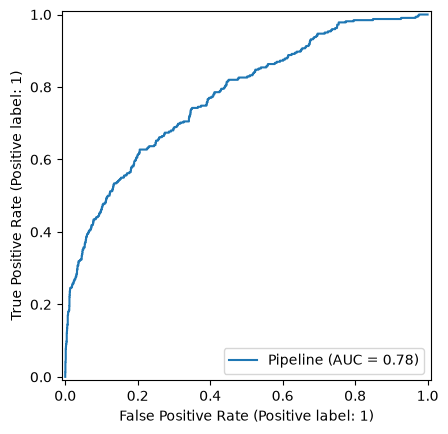

In [23]:
RocCurveDisplay.from_estimator(gb_cv.best_estimator_, test_featuers, test_targets)

In [24]:
proba = gb_cv.best_estimator_.predict_proba(test_featuers)[:, 1]
print(round(roc_auc_score(test_targets, proba), 3))

0.776


### ROC-kurven og AUC

ROC-kurven ligger tydelig over diagonalen. Den stiger bratt til venstre: modellen fanger ca. 60 % av målene når ca. 20 % av bommene feilaktig kalles mål, og ca. 77 % av målene ved ca. 40 %. AUC er ca. 0,77. Tallet varierer litt mellom kjøringene mine (0,771 og 0,776), fordi jeg ikke har satt random_state.

For en xG-modell er det et godt resultat. I litteraturen oppgis StatsBombs egen xG-modell med AUC rundt 0,80 (0,801 hos Iapteff et al. og 0,805 hos Bajons og Harringer), så modellen min ligger ikke langt under. Tallene er likevel ikke direkte sammenlignbare, siden de er målt på ulike skuddutvalg.

Jeg må ikke la meg lure av dette tallet. AUC sier at rangeringen av skuddene er god, altså at mål stort sett får høyere verdi enn bom. Den sier ingenting om hvorvidt sannsynlighetene stemmer. Det så jeg over, der modellen predikerte for mange mål selv med denne AUC-en. Siden jeg skal bruke sannsynligheten som xG, må jeg sjekke det med kalibrering. Jeg forventer ikke at kalibreringen endrer AUC, siden den bare justerer nivået og ikke rekkefølgen.

Kilder: Iapteff et al. (2025), Frontiers in Sports and Active Living, https://www.frontiersin.org/articles/10.3389/fspor.2025.1504362/full. Bajons og Harringer, "One xG model to rule them all? Challenging the most accurate xG model", Hudl.

In [25]:
# En liten sjekk som viser at summen av XG til modellen er mulig å sammenligne med verklige mål
print(f"Modellen predikerer totalt: {proba.sum():.1f} mål")
print(f"I virkeligheten ble det scoret: {test_targets.sum()} mål")


Modellen predikerer totalt: 858.7 mål
I virkeligheten ble det scoret: 322 mål


### Første bevis på at modellen må kalibreres

Summen av alle sannsynlighetene på testsettet er det samme som antall mål modellen forventer. Her predikerer modellen totalt 846,8 mål, mens det faktisk ble scoret 322. Det er ca. 2,6 ganger for mange. ,mens bare ca. 13 % av skuddene i testsettet er mål. Rangeringen kan være god (AUC ca. 0,77), men sannsynlighetene er altså altfor høye.

Jeg tror årsaken er vektingen jeg gjorde før treningen, der hvert mål fikk vekt 4 og hvert ikke-mål vekt 1. For modellen er det som om målandelen i treningsdataene var ca. 39 % i stedet for 13,7 % (4 × 13,7 / (4 × 13,7 + 86,3)). Modellen har lært seg at mål er mye vanligere enn de er, og snittet på ca. 34 % ligger i samme størrelsesorden. Dette er en forklaring jeg har regnet meg frem til, ikke noe jeg har bevist ennå.

Slik som modellen er nå, kan jeg ikke bruke sannsynlighetene som xG. Jeg kalibrerer den i neste steg.

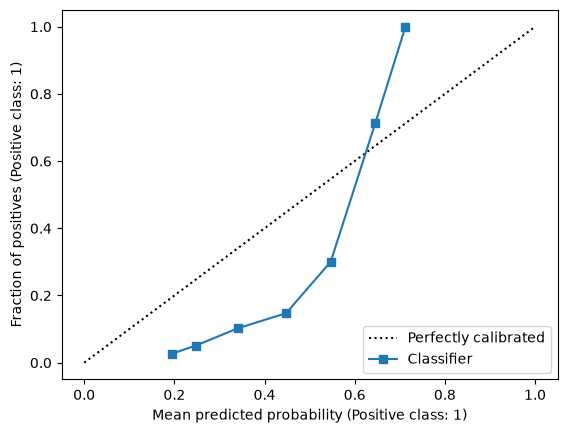

In [26]:
CalibrationDisplay.from_predictions(test_targets, proba, n_bins=10)

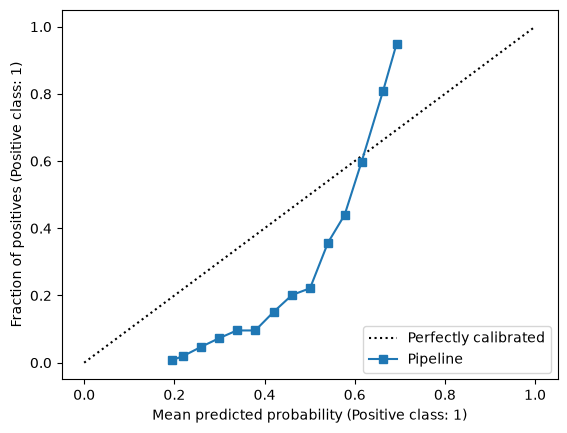

In [27]:
CalibrationDisplay.from_estimator(gb_cv.best_estimator_, trainval_featuers, trainval_target, n_bins=25)

Kalibreringskurven er et enda tydeligere bevis. På testsettet ligger kurven under diagonalen for det meste av området. Når modellen sier ca. 0,55, ble bare ca. 26 % av skuddene mål, og når den sier ca. 0,45, ble det ca. 15 %. Samme mønster ser jeg på trainval, så skjevheten ligger i modellen og ikke i testsettet. Helt til høyre er modellen derimot for forsiktig: ved ca. 0,73 ble ca. 82 % mål. Kurven er altså både forskjøvet og for bratt, og det må kalibreringen rette opp.

In [28]:
grupperte_splitter= list(inner_cv.split(trainval_featuers, trainval_target, train_groups))

calibrated_gb = CalibratedClassifierCV(
    estimator=gb_cv.best_estimator_, 
    method="sigmoid",
    cv=grupperte_splitter,
    ensemble=False
)

calibrated_gb.fit(trainval_featuers, trainval_target, 
                  estimator__sample_weight=sample_goals)


,"estimator estimator: estimator instance, default=NoneThe classifier whose output need to be calibrated to provide moreaccurate `predict_proba` outputs. The default classifier isa :class:`~sklearn.svm.LinearSVC`... versionadded:: 1.2",Pipeline(step...sample=0.7))])
,"cv cv: int, cross-validation generator, or iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross-validation,- integer, to specify the number of folds,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if ``y`` is binary or multiclass,:class:`~sklearn.model_selection.StratifiedKFold` is used. If ``y`` isneither binary nor multiclass, :class:`~sklearn.model_selection.KFold`is used.Refer to the :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.","[(array([ 0,...shape=(8399,)), ...), (array([ 0,...shape=(8423,)), ...), ...]"
,"ensemble ensemble: bool, or ""auto"", default=""auto""Determines how the calibrator is fitted.""auto"" will use `False` if the `estimator` is a:class:`~sklearn.frozen.FrozenEstimator`, and `True` otherwise.If `True`, the `estimator` is fitted using training data, andcalibrated using testing data, for each `cv` fold. The final estimatoris an ensemble of `n_cv` fitted classifier and calibrator pairs, where`n_cv` is the number of cross-validation folds. The output is theaverage predicted probabilities of all pairs.If `False`, `cv` is used to compute unbiased predictions, via:func:`~sklearn.model_selection.cross_val_predict`, which are thenused for calibration. At prediction time, the classifier used is the`estimator` trained on all the data.Note that this method is also internally implemented in:mod:`sklearn.svm` estimators with the `probabilities=True` parameter... versionadded:: 0.24.. versionchanged:: 1.6 `""auto""` option is added and is the default.",False
,"method method: {'sigmoid', 'isotonic', 'temperature'}, default='sigmoid'The method to use for calibration. Can be:- 'sigmoid', which corresponds to Platt's method (i.e. a binary logistic regression model).- 'isotonic', which is a non-parametric approach.- 'temperature', temperature scaling.Sigmoid and isotonic calibration methods natively support only binaryclassifiers and extend to multi-class classification using a One-vs-Rest (OvR)strategy with post-hoc renormalization, i.e., adjusting the probabilities aftercalibration to ensure they sum up to 1.In contrast, temperature scaling naturally supports multi-class calibration byapplying `softmax(classifier_logits/T)` with a value of `T` (temperature)that optimizes the log loss.For very uncalibrated classifiers on very imbalanced datasets, sigmoidcalibration might be preferred because it fits an additional interceptparameter. This helps shift decision boundaries appropriately when theclassifier being calibrated is biased towards the majority class.Isotonic calibration is not recommended when the number of calibration samplesis too low ``(≪1000)`` since it then tends to overfit... versionchanged:: 1.8 Added option 'temperature'.",'sigmoid'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors.Base estimator clones are fitted in parallel across cross-validationiterations.See :term:`Glossary <n_jobs>` for more details... versionadded:: 0.24",None
Name,Type,Value
"calibrated_classifiers_ calibrated_classifiers_: list (len() equal to cv or 1 if `ensemble=False`)The list of classifier and calibrator pairs.- When `ensemble=True`, `n_cv` fitted `estimator` and calibrator pairs. `n_cv` is the number of cross-validation folds.- When `ensemble=False`, the `estimator`, fitted on all the data, and fitted calibrator... versionchanged:: 0.24 Single calibrated class

In [29]:
oog_propa = cross_val_predict(
    CalibratedClassifierCV(estimator=gb_cv.best_estimator_, method='sigmoid', cv=3, ensemble=False),
    trainval_featuers, trainval_target, cv=grupperte_splitter, method="predict_proba",
    params={"estimator__sample_weight": sample_goals}
)[:, 1]

### Ærlige sannsynligheter på trainval

`calibrated_gb` er trent på alle trainval-skuddene. Hvis jeg kjører den på trainval, har den allerede sett skuddene, og sannsynlighetene blir for pene. Derfor lager jeg egne ærlige sannsynligheter med cross_val_predict.

`cross_val_predict` deler dataene i folds, trener en modell på alle foldene unntatt én, og predikerer den som ble holdt utenfor. Det gjentas til alle foldene har vært utenfor én gang. Resultatet er én sannsynlighet per skudd, fra en modell som ikke har trent på akkurat det skuddet. Jeg bruker 5 folds gruppert på kamp, slik at alle skudd fra samme kamp er i samme fold. I hver runde trener og kalibrerer jeg en hel CalibratedClassifierCV på 4 folds og predikerer den siste.

Jeg bruker disse sannsynlighetene til to ting: å sjekke at kalibreringen virker (kurve og sum mot faktiske mål) før jeg rører testsettet, og senere til å velge terskel. Den indre kalibreringen i hver runde (cv=3) er ikke gruppert på kamp. Det er en svakhet jeg er klar over.

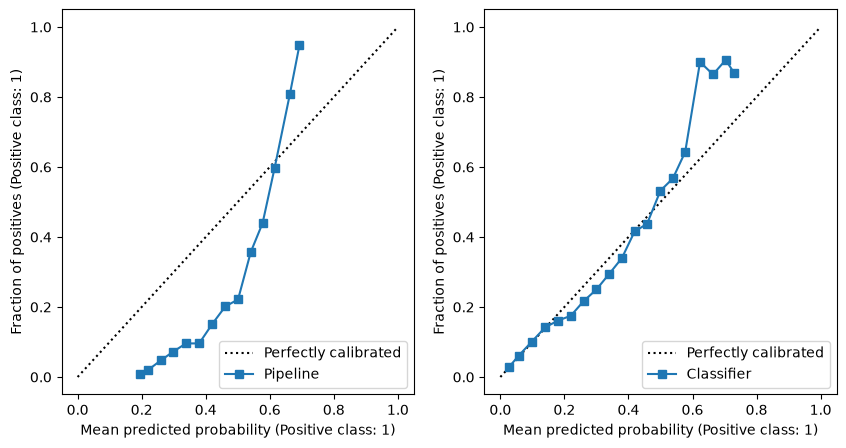

In [30]:
fig, ax= plt.subplots(1, 2, figsize=(10,5))
CalibrationDisplay.from_estimator(gb_cv.best_estimator_, trainval_featuers, trainval_target, n_bins=25, ax=ax[0])
CalibrationDisplay.from_predictions(trainval_target, oog_propa, n_bins=25, ax=ax[1])

### Forskjellen mellom den ukalibrerte og den kalibrerte modellen

Figuren viser kalibreringskurven for den ukalibrerte modellen (til venstre) og for den kalibrerte modellen (til høyre), begge på trainval.

Den ukalibrerte modellen ligger langt under diagonalen i det meste av området. Når den sier ca. 0,5, ble bare ca. 19 % mål, og når den sier ca. 0,3, ble det ca. 7 %. Den kalibrerte modellen ligger tett på diagonalen: ved ca. 0,5 ble ca. 55 % mål, og ved ca. 0,3 ca. 28 %. Kalibreringen har altså rettet opp nivået, som var for høyt på grunn av vektingen jeg brukte (mål vekt 4, ikke-mål vekt 1).

Sammenligningen er ikke helt lik. Den ukalibrerte modellen er målt på skudd den er trent på, mens den kalibrerte er målt på ærlige sannsynligheter fra cross_val_predict. Data modellen er trent på pleier å se penere ut enn nye data, så den ukalibrerte kurven burde om noe sett bedre ut. At den likevel er så mye dårligere, styrker poenget.

Kalibrering endrer nivået på sannsynlighetene, ikke hvilke skudd som rangeres høyest. Det er den samme modellen i bunn.

Det er fortsatt et lite avvik. Ved ca. 0,2–0,3 ligger kurven litt under diagonalen, og helt til høyre (0,6–0,75) ligger den over, med 0,9–1,0 som faktisk andel. De øverste punktene bygger trolig på få skudd, så de er usikre. Sigmoid-kalibrering kan justere skift og helning, men ikke alle former.

In [31]:
print(f"Predikert: {oog_propa.sum():.0f}  faktisk: {trainval_target.sum()}")

Predikert: 1467  faktisk: 1453


Etter kalibreringen predikerer modellen 1464 mål på ærlige prediksjoner fra trainval, mens det faktisk ble scoret 1453. Avviket er 11 mål, under 1 %. Før kalibreringen var summen 846,8 mot 322 på testsettet, altså 2,6 ganger for mange. Summen sier bare at nivået stemmer i snitt, og den er delvis å forvente siden kalibrering er laget for å få det til. Kalibreringskurven viser hvordan det ser ut for ulike sannsynlighetsnivåer, og den viser et lite restavvik. Den uavhengige testen av kalibreringen er testsettet.

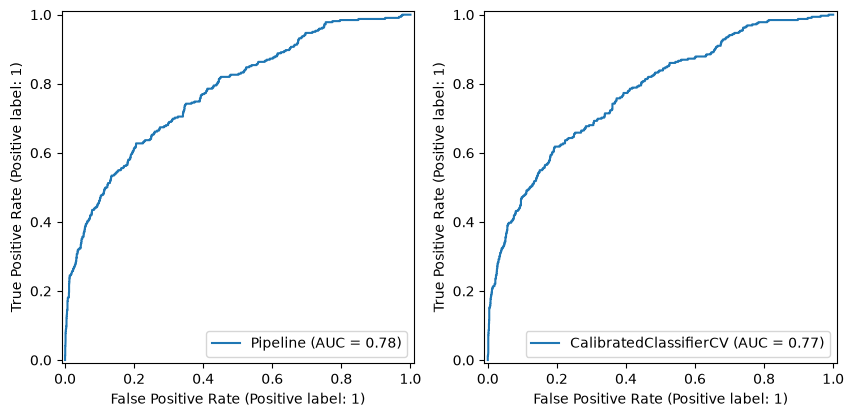

In [32]:
fig, ax = plt.subplots(1, 2, figsize=(10, 5))

RocCurveDisplay.from_estimator(gb_cv.best_estimator_, test_featuers, test_targets, ax=ax[0])
RocCurveDisplay.from_estimator(calibrated_gb, test_featuers, test_targets ,ax=ax[1])

ROC-kurvene før og etter kalibrering ser nesten like ut, og AUC er 0,77 i begge. Kalibreringen endrer altså nivået på sannsynlighetene, men ikke hvor godt modellen rangerer skuddene. Den små forskjellen mellom kurvene kommer trolig av at den kalibrerte modellen er trent på nytt, og at det er tilfeldighet i Gradient Boosting.

In [33]:
# Hent ut de EKTE kalibrerte xG-sannsynlighetenene
proba_calibrated = calibrated_gb.predict_proba(test_featuers)[:, 1]

# Sjekk de ekte resultatene
print("--- EKTE KALIBRERING ---")
print(f"Modellen predikerer totalt: {proba_calibrated.sum():.1f} mål")
print(f"I virkeligheten ble det scoret: {test_targets.sum()} mål")
print(f"Ekte, kalibrert ROC-AUC Score: {roc_auc_score(test_targets, proba_calibrated):.3f}")


--- EKTE KALIBRERING ---
Modellen predikerer totalt: 333.1 mål
I virkeligheten ble det scoret: 322 mål
Ekte, kalibrert ROC-AUC Score: 0.775


### Kalibrert modell på testsettet

Dette er første gang jeg bruker den kalibrerte modellen på testsettet. Kalibreringen er lært bare fra trainval, så resultatet er uavhengig.

- **Summen av sannsynlighetene:** modellen predikerer 333,8 mål, mens det ble scoret 322. Det er ca. 4 % for mange. Den ukalibrerte modellen predikerte 846,8, altså ca. 2,6 ganger for mange.
- **Hva summen betyr:** den er summen av xG over alle skuddene, altså hvor mange mål modellen forventer totalt. Den betyr ikke at modellen finner alle målene. Hvis den gjorde det, ville recall vært over 90 %, og det er den langt fra. Målene er spredt over mange skudd med lave sannsynligheter.
- **Rangering:** AUC er 0,772 for den kalibrerte modellen mot ca. 0,77 for den ukalibrerte. Kalibreringen har endret nivået på sannsynlighetene, men ikke hvor godt modellen rangerer skuddene.
- **Restavvik:** summen er litt for høy. Det går i samme retning som kalibreringskurven, der modellen lå litt over diagonalen ved lave sannsynligheter.

In [34]:
class ThresholdClassifier(BaseEstimator, ClassifierMixin):
    def __init__(self, estimator, threshold=0.5):
        self.estimator = estimator
        self.threshold = threshold

    def fit(self, x, y):
        if hasattr(self.estimator, 'classes_'):
            self.classes_ = self.estimator.classes_
            return self
        self.estimator.fit(x, y)
        return self

    def predict(self, x):
        probabilities = self.predict_proba(x)
        # Bruker self.threshold i stedet for bare threshold
        return (probabilities[:, 1] >= self.threshold).astype(int)

    def predict_proba(self, x):
        return self.estimator.predict_proba(x)


In [35]:
thresholds = np.arange(0.05, 0.80, 0.05)

results = []
for t in thresholds:
    preds = (oog_propa >= t).astype(int)
    results.append({
        'Terskel (Threshold)': round(t, 2),
        'F1-Score': round(f1_score(trainval_target, preds), 4),
        'Precision (Presisjon)': round(precision_score(trainval_target, preds, zero_division=0), 4),
        'Recall (Sensitivitet)': round(recall_score(trainval_target, preds), 4)
    })

df_results = pd.DataFrame(results)
print(df_results.to_string(index=False))

best_row = df_results.loc[df_results['F1-Score'].idxmax()]
best_threshold = best_row['Terskel (Threshold)']
print(f"\nBeste terskel for F1: {best_threshold}  (F1 = {best_row['F1-Score']})")

 Terskel (Threshold)  F1-Score  Precision (Presisjon)  Recall (Sensitivitet)
                0.05    0.3477                 0.2152                 0.9043
                0.10    0.4236                 0.2893                 0.7908
                0.15    0.4549                 0.3322                 0.7213
                0.20    0.4763                 0.3739                 0.6559
                0.25    0.4889                 0.4093                 0.6070
                0.30    0.4952                 0.4490                 0.5520
                0.35    0.4797                 0.4913                 0.4687
                0.40    0.4535                 0.5596                 0.3813
                0.45    0.3860                 0.6346                 0.2774
                0.50    0.3248                 0.7100                 0.2106
                0.55    0.2577                 0.8222                 0.1528
                0.60    0.2121                 0.8883                 0.1204

### Terskelvalg

For en xG-modell er ikke poenget å si mål eller ikke mål, men å gi sannsynligheten for at skuddet blir mål. Det klarer modellen min å rangere godt, og det synes jeg er det mest positive: i ca. 77 % av tilfellene (AUC) gir den et skudd som ble mål høyere sannsynlighet enn et skudd som ikke ble mål. En terskel trengs bare hvis jeg vil ha en hard merkelapp, for eksempel «stor sjanse», og det gjør jeg her fordi oppgaven krever det.

Jeg har sveipet terskelen på de ærlige sannsynlighetene fra trainval (ikke testsettet), med F1, precision og recall:

- **0,25:** F1 0,489. Modellen fanger ca. 60 % av målene, og ca. 41 % av skuddene den kaller mål blir mål.
- **0,30:** F1 0,492, som er høyest. Den fanger ca. 54 %, og ca. 45 % av skuddene den kaller mål blir mål.
- F1 er nesten lik ved 0,25 og 0,30. Å gå fra 0,25 til 0,30 gir litt høyere presisjon, men færre mål fanget.
- Lavere terskler fanger flere mål, men med mange falske alarmer (ved 0,05 er recall 89 %, men bare 22 % presisjon). Høyere terskler er veldig presise, men fanger nesten ingenting (ved 0,60 er presisjonen 90 %, men recall bare 13 %).

Jeg synes derfor en terskel mellom 0,25 og 0,30 er et rimelig valg. Å velge terskel er en avveining mellom å fange mål og å ta feil, ikke et riktig svar, og det kommer jeg tilbake til i rapporten.

In [36]:
valgt_terskel = 0.25  

deploy_modell = ThresholdClassifier(estimator=calibrated_gb, threshold=valgt_terskel)
deploy_modell.fit(trainval_featuers, trainval_target)   # gjør ingenting, men setter classes_

proba_test  = deploy_modell.predict_proba(test_featuers)[:, 1]
y_pred_test = deploy_modell.predict(test_featuers)

print("Terskel:", valgt_terskel)
print("ROC-AUC:", round(roc_auc_score(test_targets, proba_test), 3))
print(f"Predikert sum: {proba_test.sum():.0f}  faktisk: {test_targets.sum()}")
print("F1:", round(f1_score(test_targets, y_pred_test), 3))
print("Precision:", round(precision_score(test_targets, y_pred_test), 3))
print("Recall:", round(recall_score(test_targets, y_pred_test), 3))

Terskel: 0.25
ROC-AUC: 0.775
Predikert sum: 333  faktisk: 322
F1: 0.427
Precision: 0.37
Recall: 0.506


### Endelig evaluering på testsettet

Terskelen (0,25) er valgt på trainval, og testsettet er først brukt nå.

- **Rangering og nivå:** ROC-AUC er 0,772, og modellen predikerer 334 mål mot 322 faktiske.
- **Ved terskel 0,25:** F1 er 0,42, precision 0,361 og recall 0,503. Modellen fanger altså omtrent halvparten av målene, og ca. 36 % av skuddene den kaller mål ble mål.
- **Sammenlignet med trainval** (F1 0,489, precision 0,411, recall 0,605) er alle tre lavere på test. Det er forventet, siden terskelen er valgt på trainval og testsettet er andre sesonger. Målandelen er også litt lavere på test (ca. 13 % mot ca. 14 %), og det gir lavere precision, men forklarer ikke hele forskjellen.
- Jeg endrer ikke terskelen etter å ha sett testresultatet, siden det ville betydd å velge på testsettet.

In [ ]:
deploy_modell_tuned= TunedThresholdClassifierCV(calibrated_gb, cv= inner_cv, scoring=[make_scorer(fbeta_score, beta = 0.99)])
deploy_modell.fit(trainval_featuers, trainval_target)

In [37]:
with open("GB_XG_model.pickle","wb") as f:
    p.dump(deploy_modell, f)

In [38]:
print(deploy_modell)

ThresholdClassifier(estimator=CalibratedClassifierCV(cv=[(array([    0,     1,     2, ..., 10504, 10505, 10506], shape=(8399,)),
                                                          array([  144,   145,   146, ..., 10362, 10363, 10364], shape=(2108,))),
                                                         (array([    0,     1,     2, ..., 10453, 10454, 10455], shape=(8423,)),
                                                          array([  122,   123,   124, ..., 10504, 10505, 10506], shape=(2084,))),
                                                         (array([   29,    30,    31, ..., 10504, 10505, 10506], shape=(8386,)),
                                                          array([    0,     1,     2, ..., 1...
                                                                                                                  'position',
                                                                                                                  'shot_body_part',

In [39]:
import  sklearn
with open("GB_XG_model.pickle", "rb") as f:
    lastet = p.load(f)

print(np.array_equal(lastet.predict_proba(test_featuers), deploy_modell.predict_proba(test_featuers)))
print(np.array_equal(lastet.predict(test_featuers), deploy_modell.predict(test_featuers)))
print(sklearn.__version__)

True
True
1.9.1


In [40]:
from urllib.parse import urlencode

rad = test_featuers.iloc[0]
verdier = {k: (int(v) if isinstance(v, (bool, np.bool_)) else v) for k, v in rad.items()}
print("http://127.0.0.1:5000/predict?" + urlencode(verdier))

# fasit å sammenligne med:
print(deploy_modell.predict_proba(test_featuers.iloc[[0]])[0, 1])
print(deploy_modell.predict(test_featuers.iloc[[0]])[0])

http://127.0.0.1:5000/predict?team=Barcelona&position=Left+Wing&shot_body_part=Right+Foot&shot_technique=Normal&shot_type=Open+Play&under_pressure=0&shot_follows_dribble=0&shot_aerial_won=0&shot_first_time=0&shot_one_on_one=1&shot_open_goal=0&minute=12&location_x=108.6&location_y=28.0&keeper_x=114.5&keeper_y=33.8&shot_distance_from_goal=16.55173706896047&shot_angle=46.46880071438581&shot_angle_visual=19.470700865712978&distance_between_shooter_and_keeper=8.273451516749224&distance_between_keeper_and_goal=8.28794304999739&opponents_within_2_5_yards=0.0&opponents_2_5_to_5_yards=1.0&opponents_5_to_10_yards=0.0&distance_to_nearest_opponent=2.863564212655265&opponents_in_shot_triangle=0.0&goals_for_before=0&goals_against_before=0&score_diff_before=0&player_goal_rate_before=0.23073083552763765&shots_before=35
0.331565559343914
1


In [41]:
for i in range(5):
    rad = test_featuers.iloc[i]
    verdier = {k: (int(v) if isinstance(v, (bool, np.bool_)) else v) for k, v in rad.items()}
    print(i, "http://127.0.0.1:5000/predict?" + urlencode(verdier))
    print("   fasit xG:", deploy_modell.predict_proba(test_featuers.iloc[[i]])[0, 1])

0 http://127.0.0.1:5000/predict?team=Barcelona&position=Left+Wing&shot_body_part=Right+Foot&shot_technique=Normal&shot_type=Open+Play&under_pressure=0&shot_follows_dribble=0&shot_aerial_won=0&shot_first_time=0&shot_one_on_one=1&shot_open_goal=0&minute=12&location_x=108.6&location_y=28.0&keeper_x=114.5&keeper_y=33.8&shot_distance_from_goal=16.55173706896047&shot_angle=46.46880071438581&shot_angle_visual=19.470700865712978&distance_between_shooter_and_keeper=8.273451516749224&distance_between_keeper_and_goal=8.28794304999739&opponents_within_2_5_yards=0.0&opponents_2_5_to_5_yards=1.0&opponents_5_to_10_yards=0.0&distance_to_nearest_opponent=2.863564212655265&opponents_in_shot_triangle=0.0&goals_for_before=0&goals_against_before=0&score_diff_before=0&player_goal_rate_before=0.23073083552763765&shots_before=35
   fasit xG: 0.331565559343914
1 http://127.0.0.1:5000/predict?team=Deportivo+Alav%C3%A9s&position=Right+Midfield&shot_body_part=Right+Foot&shot_technique=Normal&shot_type=Open+Play&u

In [49]:
perm = permutation_importance(
    calibrated_gb, test_featuers, test_targets,
    scoring="roc_auc", n_repeats=20, random_state=42, n_jobs=-1)

perm_df = (pd.DataFrame({"feature": test_featuers.columns,
                         "mean": perm.importances_mean,
                         "std": perm.importances_std})
           .sort_values("mean", ascending=False))
pd.set_option("display.float_format", "{:.4f}".format)
print(perm_df)


                                feature    mean    std
18                    shot_angle_visual  0.0398 0.0074
19  distance_between_shooter_and_keeper  0.0255 0.0070
2                        shot_body_part  0.0117 0.0019
24         distance_to_nearest_opponent  0.0063 0.0016
25           opponents_in_shot_triangle  0.0040 0.0014
16              shot_distance_from_goal  0.0039 0.0026
14                             keeper_x  0.0037 0.0018
7                       shot_aerial_won  0.0036 0.0007
20     distance_between_keeper_and_goal  0.0034 0.0015
4                             shot_type  0.0016 0.0008
10                       shot_open_goal  0.0014 0.0009
17                           shot_angle  0.0014 0.0004
29              player_goal_rate_before  0.0010 0.0009
21           opponents_within_2_5_yards  0.0009 0.0003
30                         shots_before  0.0008 0.0014
5                        under_pressure  0.0002 0.0002
8                       shot_first_time  0.0002 0.0002
3         

In [53]:
perm_res = permutation_importance(
    calibrated_gb, trainval_featuers, trainval_target,
    scoring="roc_auc", n_repeats=20, random_state=42, n_jobs=-1)

sammenlign = pd.DataFrame({
    "feature": trainval_featuers.columns,
    "test": perm.importances_mean,
    "trainval": perm_res.importances_mean}).sort_values("test", ascending=False)
print(sammenlign.round(4))

                                feature    test  trainval
18                    shot_angle_visual  0.0398    0.0399
19  distance_between_shooter_and_keeper  0.0255    0.0331
2                        shot_body_part  0.0117    0.0084
24         distance_to_nearest_opponent  0.0063    0.0066
25           opponents_in_shot_triangle  0.0040    0.0028
16              shot_distance_from_goal  0.0039    0.0059
14                             keeper_x  0.0037    0.0061
7                       shot_aerial_won  0.0036    0.0023
20     distance_between_keeper_and_goal  0.0034    0.0055
4                             shot_type  0.0016    0.0022
10                       shot_open_goal  0.0014    0.0016
17                           shot_angle  0.0014    0.0012
29              player_goal_rate_before  0.0010    0.0027
21           opponents_within_2_5_yards  0.0009    0.0006
30                         shots_before  0.0008    0.0030
5                        under_pressure  0.0002    0.0003
8             

### Feature importance: permutation importance

Jeg måler hvor mye ROC-AUC faller når en feature blandes tilfeldig (20 blandinger per feature), først på testsettet og deretter på trainval som kontroll. Jeg bruker AUC som mål fordi det passer med at modellen skal rangere skudd etter sannsynlighet.

**De viktigste featurene er de samme i begge sett:**
- `shot_angle_visual` er klart viktigst, med et fall på ca. 0,040 både på test (0,0398) og trainval (0,0399).
- `distance_between_shooter_and_keeper` kommer deretter (test 0,026, trainval 0,033), og så `shot_body_part` (0,012 og 0,008) og `distance_to_nearest_opponent` (0,006 og 0,007).

**Svake features:** `team`, `position`, `minute`, `keeper_y` og `score_diff_before` ligger rundt 0 på testsettet. Modellen bruker dem altså ikke til å rangere nye skudd. På trainval får noen av dem små positive verdier (f.eks. `team` 0,0010 og `location_x` 0,0020), som tyder på en liten tilpasning til støy i treningsdataene. Forskjellene er bare rundt 0,001–0,003 i AUC, så jeg vurderer overtilpasningen som liten.

**Forbehold:** `shot_distance_from_goal`, `shot_angle_visual` og `distance_between_shooter_and_keeper` måler delvis det samme. Når én blandes, kan de andre dekke opp, så tallene viser hvor mye modellen mister, ikke hvor viktig hver feature er i seg selv.

Neste steg er å plotte disse resultatene.

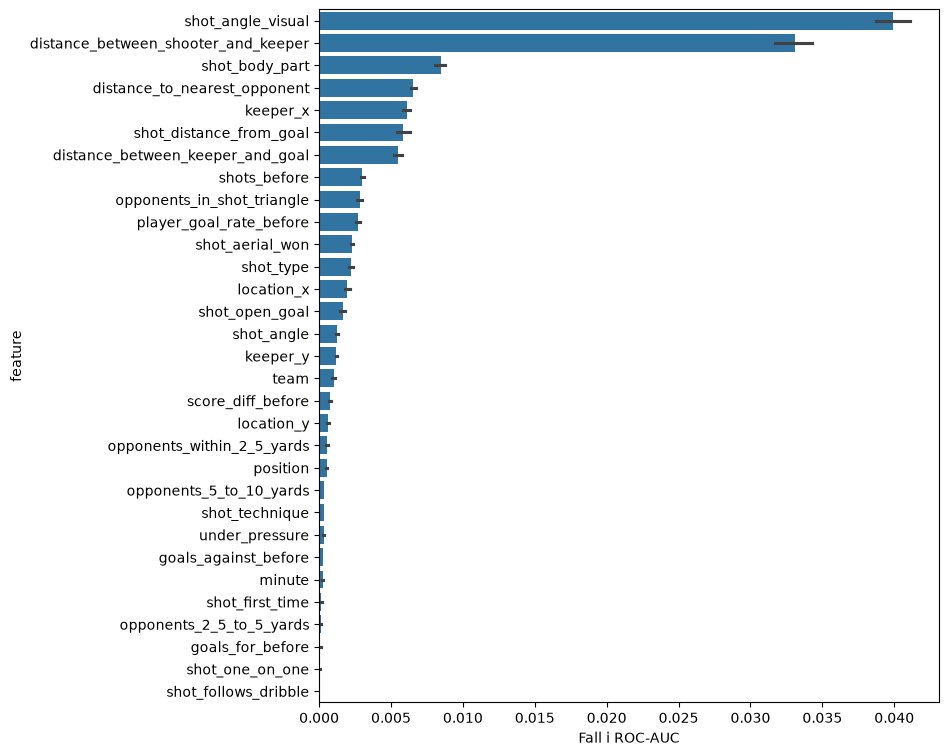

In [54]:
results_frame_raw = pd.DataFrame({column: perm_res.importances[i]
                                  for i, column in enumerate(trainval_featuers.columns)})
results_frame_raw = results_frame_raw.melt(value_vars=results_frame_raw.columns,
                                           var_name='feature', value_name='importance')

order = results_frame_raw.groupby('feature')['importance'].mean().sort_values(ascending=False).index

plt.figure(figsize=(8, 9))
sb.barplot(data=results_frame_raw, x='importance', y='feature', order=order)
plt.xlabel("Fall i ROC-AUC")
plt.show()

**Permutation importance på trainval**

Grafen viser fallet i ROC-AUC per feature på trainval (20 blandinger, feilstolpene er 95 % konfidensintervall).

- `shot_angle_visual` (ca. 0,040) og `distance_between_shooter_and_keeper` (ca. 0,033) skiller seg klart ut, og resten ligger under 0,01.
- Deretter kommer `shot_body_part` (ca. 0,008), `distance_to_nearest_opponent`, `keeper_x`, `shot_distance_from_goal` og `distance_between_keeper_and_goal` (alle ca. 0,006).
- Spillerhistorikk (`shots_before` og `player_goal_rate_before`) ligger høyere her (ca. 0,003) enn på testsettet. Det kan tyde på at modellen har tilpasset seg litt til spillerne i treningsdataene.
- Nederst ligger features som `shot_follows_dribble`, `shot_one_on_one` og `goals_for_before`, som modellen nesten ikke bruker.
- Feilstolpene er små siden trainval har mange skudd (ca. 10 500), men de sier bare noe om støy fra selve blandingen. De sier ikke at tallene er like nøyaktige på nye data.

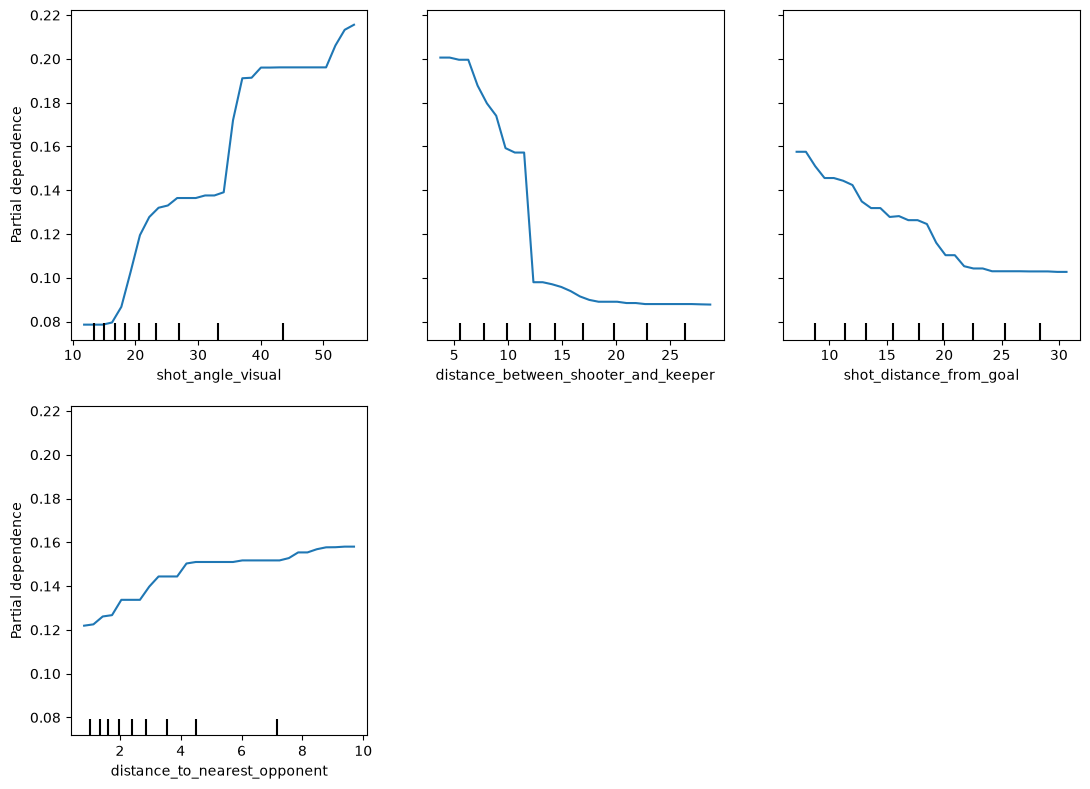

In [57]:
pdp_features = ["shot_angle_visual", "distance_between_shooter_and_keeper",
                "shot_distance_from_goal", "distance_to_nearest_opponent"]

disp = PartialDependenceDisplay.from_estimator(
    calibrated_gb, test_featuers, pdp_features,
    kind="average", grid_resolution=30, n_jobs=-1)
disp.figure_.set_size_inches(11, 8)
plt.tight_layout()
plt.show()

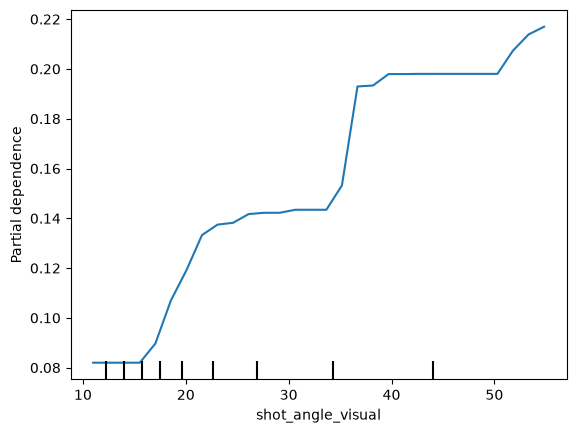

In [ ]:
disp_angle= PartialDependenceDisplay.from_estimator(
    calibrated_gb, trainval_featuers, ["shot_angle_visual"],
    kind="average", grid_resolution=30, n_jobs=-1
)

**Partial dependence: `shot_angle_visual`**

Grafen viser at jo større vinkelen er, desto høyere xG gir modellen i gjennomsnitt. For små vinkler (under ca. 16) ligger xG flatt på ca. 0,08. Mellom ca. 17 og 24 stiger den raskt til ca. 0,13, og ved ca. 35–37 er det et nytt hopp opp til ca. 0,19–0,20. Til slutt stiger den litt til ca. 0,22 for de største vinklene.


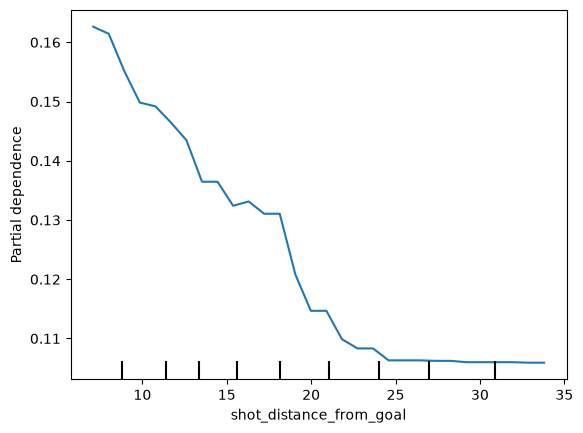

In [61]:
disp_distance= PartialDependenceDisplay.from_estimator(
    calibrated_gb, trainval_featuers, ["shot_distance_from_goal"],
    kind="average", grid_resolution=30, n_jobs=-1 
)

**Partial dependence: `shot_distance_from_goal`**

Her er sammenhengen motsatt av vinkelen: jo kortere avstand til mål, desto høyere xG. Ved de korteste avstandene (ca. 7–8) er gjennomsnittlig xG ca. 0,16, og den faller jevnt til ca. 0,13 rundt avstand 15–18. Det er et tydelig fall mellom ca. 18 og 23, og over ca. 25 flater kurven ut på ca. 0,106, så lengre skudd har omtrent lik (lav) xG uansett avstand.

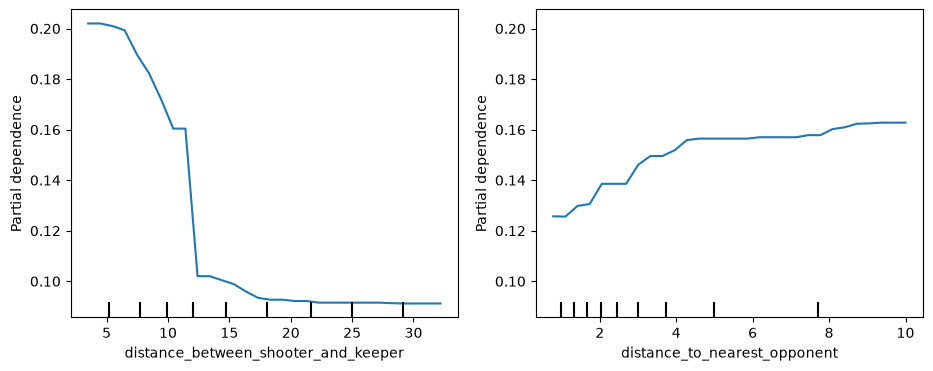

In [70]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

PartialDependenceDisplay.from_estimator(
    calibrated_gb, trainval_featuers,
    ["distance_between_shooter_and_keeper", "distance_to_nearest_opponent"],
    kind="average", grid_resolution=30, n_jobs=-1, ax=axes)

**Partial dependence: `distance_between_shooter_and_keeper` og `distance_to_nearest_opponent`**

- **Avstand mellom skytter og keeper:** Jo nærmere keeperen skytteren er, desto høyere xG. Ved 3–6 yards er xG ca. 0,20, og den faller til ca. 0,16 rundt 11 yards. Det er et skarpt fall mellom ca. 11 og 13 yards (til ca. 0,10), og deretter flater kurven ut på ca. 0,09 for avstander over 20 yards. Dette er den featuren som endrer xG mest (variasjon på ca. 0,11).
- **Avstand til nærmeste motstander:** Jo mer plass skytteren har, desto høyere xG. xG stiger fra ca. 0,126 ved 1 yard til ca. 0,157 ved 4–5 yards, og stiger deretter svakt til ca. 0,163 ved 10 yards. Effekten er mindre (variasjon på ca. 0,04), og strekene nederst viser at de fleste skudd har en motstander nærmere enn 4 yards, så høyre del av kurven bygger på få skudd.

Avstanden til keeper henger sammen med avstand til mål og vinkelen, så effekten kan ikke tolkes helt isolert fra dem.

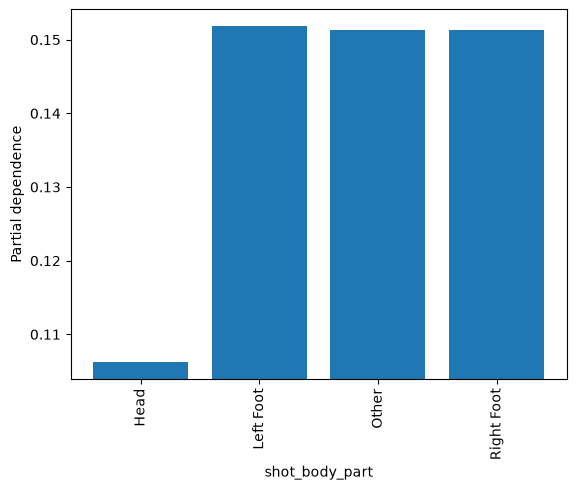

In [62]:
disp_body = PartialDependenceDisplay.from_estimator(
    calibrated_gb, trainval_featuers, ["shot_body_part"],
    categorical_features=["shot_body_part"],
    kind="average", n_jobs=-1)

In [64]:
(trainval_featuers.assign(mål=trainval_target)
    .groupby("shot_body_part")["mål"].agg(["mean", "count"]))

,mean,count
shot_body_part,,
Head,0.1112,1313
Left Foot,0.1475,3817
Other,0.3043,23
Right Foot,0.1377,5354


**Partial dependence: `shot_body_part`**

Modellen gir lavere xG til hodeskudd (ca. 0,106) enn til skudd med foten (ca. 0,15). Det stemmer med dataene: bare ca. 11 % av hodeskuddene (1 313 skudd) ble mål, mot ca. 14–15 % for fot-skudd (venstre 3 817, høyre 5 354). Venstre og høyre fot får nesten lik xG (0,152 og 0,151), så modellen ser ingen forskjell mellom føttene, og forskjellen i dataene (14,8 % mot 13,8 %) er liten.